# Задача 4: Множества точек на комплексной плоскости

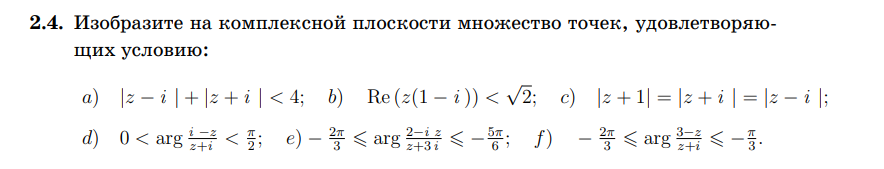

## Математическая база

### Основные понятия

Пусть $z = x + iy$ — комплексное число.

| Обозначение | Смысл | Геометрия |
|:---:|:---|:---|
| $|z - z_0| = R$ | Расстояние от $z$ до $z_0$ равно $R$ | Окружность радиуса $R$ с центром $z_0$ |
| $|z - z_1| + |z - z_2| = 2a$ | Сумма расстояний до двух фокусов постоянна | Эллипс |
| $|z - z_1| = |z - z_2|$ | Равноудалённость от двух точек | Серединный перпендикуляр |
| $\operatorname{Re}(z) = c$ | Вещественная часть постоянна | Вертикальная прямая |
| $\arg(z) = \varphi$ | Угол постоянен | Луч из начала координат |
| $\varphi_1 < \arg(z) < \varphi_2$ | Угол в диапазоне | Угловой сектор |

### Ключевые формулы

**Дробно-линейное преобразование:**
$$w = \frac{az + b}{cz + d}, \quad ad - bc \neq 0$$
сохраняет окружности и прямые (прямая = окружность бесконечного радиуса).

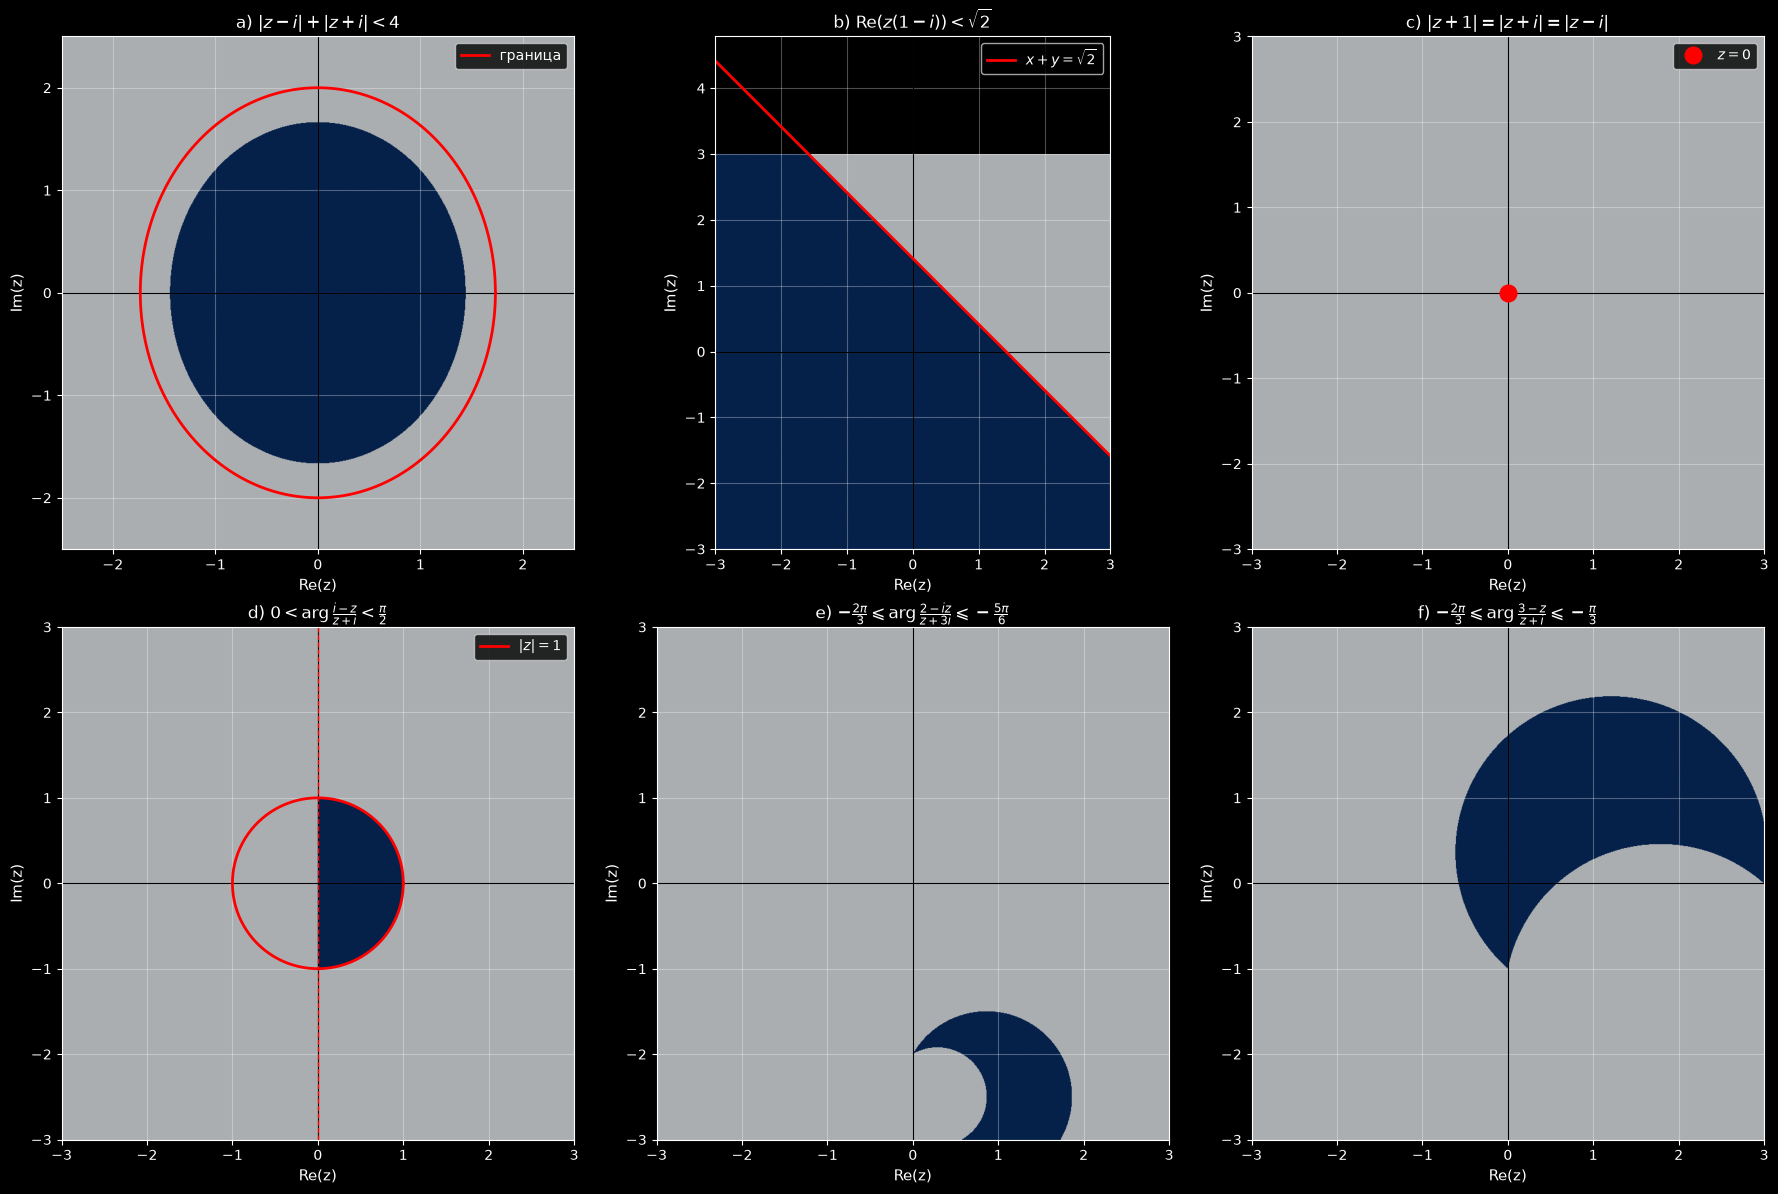

In [5]:
import numpy as np
import matplotlib.pyplot as plt

N = 800
x = np.linspace(-3, 3, N)
y = np.linspace(-3, 3, N)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

# a) |z - i| + |z + i| < 4
mask_a = np.abs(Z - 1j) + np.abs(Z + 1j) < 4

# b) Re(z(1-i)) < √2
mask_b = (X + Y) < np.sqrt(2)

# c) |z+1| = |z+i| = |z-i|
mask_c = (np.abs(np.abs(Z+1) - np.abs(Z+1j)) < 0.02) & \
         (np.abs(np.abs(Z+1j) - np.abs(Z-1j)) < 0.02)

# d) 0 < arg((i-z)/(z+i)) < π/2
with np.errstate(divide='ignore', invalid='ignore'):
    w_d = (1j - Z) / (Z + 1j)
    arg_d = np.angle(w_d)
mask_d = (arg_d > 0) & (arg_d < np.pi/2)

# e) -2π/3 ≤ arg((2-iz)/(z+3i)) ≤ -5π/6
with np.errstate(divide='ignore', invalid='ignore'):
    w_e = (2 - 1j*Z) / (Z + 3j)
    arg_e = np.angle(w_e)
mask_e = (arg_e >= -5*np.pi/6) & (arg_e <= -2*np.pi/3)

# f) -2π/3 ≤ arg((3-z)/(z+i)) ≤ -π/3
with np.errstate(divide='ignore', invalid='ignore'):
    w_f = (3 - Z) / (Z + 1j)
    arg_f = np.angle(w_f)
mask_f = (arg_f >= -2*np.pi/3) & (arg_f <= -np.pi/3)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

def plot_mask(ax, mask, title, xlim=(-3,3), ylim=(-3,3)):
    ax.imshow(mask, extent=[xlim[0], xlim[1], ylim[0], ylim[1]],
              origin='lower', cmap='Blues', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Re(z)', fontsize=11)
    ax.set_ylabel('Im(z)', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

# ── a) ──────────────────────────────────────────────────
plot_mask(axes[0,0], mask_a, r'a) $|z-i|+|z+i|<4$', xlim=(-2.5,2.5), ylim=(-2.5,2.5))
theta = np.linspace(0, 2*np.pi, 200)
axes[0,0].plot(np.sqrt(3)*np.cos(theta), 2*np.sin(theta), 'r-', linewidth=2, label='граница')
axes[0,0].legend()

# ── b) ─────────────────────────────────────────────────
plot_mask(axes[0,1], mask_b, r'b) $\mathrm{Re}(z(1-i))<\sqrt{2}$')
t = np.linspace(-3, 3, 100)
axes[0,1].plot(t, np.sqrt(2) - t, 'r-', linewidth=2, label=r'$x+y=\sqrt{2}$')
axes[0,1].legend()

# ── c) ──────────────────────────────────────────────────
plot_mask(axes[0,2], mask_c, r'c) $|z+1|=|z+i|=|z-i|$')
axes[0,2].plot(0, 0, 'ro', markersize=12, label=r'$z=0$')
axes[0,2].legend()

# ── d) ──────────────────────────────────────────────────
plot_mask(axes[1,0], mask_d, r'd) $0<\arg\frac{i-z}{z+i}<\frac{\pi}{2}$')
axes[1,0].plot(np.cos(theta), np.sin(theta), 'r-', linewidth=2, label=r'$|z|=1$')
axes[1,0].axvline(0, color='red', linewidth=1, linestyle='--')
axes[1,0].legend()

# ── e) ──────────────────────────────────────────────────
plot_mask(axes[1,1], mask_e, r'e) $-\frac{2\pi}{3}\leqslant\arg\frac{2-iz}{z+3i}\leqslant-\frac{5\pi}{6}$')

# ── f) ──────────────────────────────────────────────────
plot_mask(axes[1,2], mask_f, r'f) $-\frac{2\pi}{3}\leqslant\arg\frac{3-z}{z+i}\leqslant-\frac{\pi}{3}$')

plt.tight_layout()
plt.savefig('task_2_4.png', dpi=150)
plt.show()